# How far from the wall does the wall shear inform the flow, and does it generalise?

An experiment on Stage 1's data and model: 5,777 y–x planes of the streamwise velocity u from the channel-flow simulation (107 snapshots × up to 60 spanwise planes, 201 × 384 points), the wall gradient τ_w(x) at both walls as input, and Stage 1's 1-D U-Net.

- **Part (a): target height.** The U-Net predicts u(x) at five heights at once, y+ = 5, 10, 15, 30 and the channel centre (y+ = 125, nominal Re_τ = 125 as in Stage 1). Each height is compared with three references on the same test samples: ridge regression from the 384 wall values to the 384 target values (with the wall gradient taken into the fluid at both walls: Stage 1's input has the opposite sign at the top wall, which a single linear map cannot follow), the viscous-sublayer linear law u ≈ τ_w · (distance from the wall) (exact to first order at the wall, in the stored units), and the training mean. Every error is also divided by the target's own spread (its standard deviation over the test samples), so heights with different velocity levels can be compared; a ratio of 1 means no better than predicting the mean.
- **Part (b): generalisation.** Three splits of the same samples: Stage 1's random split (planes of the same snapshot and both walls of the same plane on both sides), a split in time (train on the earliest 80 % of snapshots, test on the latest 20 %), and a split across spanwise planes (train on planes 0–47, test on planes 48, 49 and 80–89). Same models and references on each.

Normalisation statistics and the ridge penalty come from the training part of each split only. Three seeds (0, 1, 2) for every U-Net; ridge, linear law and mean are deterministic. Training budget: at most 150 epochs with Stage 1's early stopping (patience 15) and learning-rate halving (patience 6); Stage 1's own run stopped after about 130 epochs.

# Stage 2 — How far from the wall, and does it generalise?

**Portfolio project: how much of the near-wall flow can the wall shear stress tell us?**

Stage 1 compares its U-Net with a linear-law baseline that is wrong by about a factor of a thousand (it leaves out the viscosity and flips sign at the top wall), and scores it on a random split that puts neighbouring spanwise planes of the same snapshot on both sides. Here I hold the U-Net to stricter terms, with three seeds. **Part (a)**: the U-Net predicts u(x) at y+ = 5, 10, 15, 30 and the channel centre at once, against ridge regression on the same 384 wall values, the correct first-order wall law u ≈ (du/dy)·(y − y_wall), and the training mean; every error is divided by the spread of its target, so 1 means no better than the mean. **Part (b)**: the same models on three splits — Stage 1's random split, later snapshots held out, and unseen spanwise planes held out.

**What it shows.** On held-out later snapshots the U-Net keeps an error of 0.19 of the target's spread at y+ = 5, 0.39 at 10 and 0.61 at 15, better than ridge (0.22, 0.48, 0.71) by more than its seed range; by y+ = 30 the advantage is within the seed spread (0.95 against 0.98), and at the centre neither model beats the mean. The correct wall law is competitive only at y+ = 5 (0.36). Stage 1's random split flatters both learned models by 10–17 %.

**How it connects.** It reads the same planes as Stage 1 and copies its wall gradient, y+ indices and U-Net unchanged. The device timings it reads were measured before any training (one step of each network on the CPU and on the Apple GPU).

**About the outputs.** The outputs below come from my run on 2026-10-13 (Apple M3 Max, CPU, 97 minutes; each U-Net capped at 150 epochs and every one reached the cap, so these are not converged by early stopping). Afterwards I changed only text for this repository: this cell and the paths cell, and the path lines (planes from `../release_assets/u_yx_planes_h5/`, tables and figures to `../results/02_height_and_generalisation/`).

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
PLANES = Path("../release_assets/u_yx_planes_h5")                 # the 5,777 planes, from the unet-turbulent-fields release (README)
RESULTS = Path("../results/02_height_and_generalisation")          # also holds the device timings read below
RESULTS.mkdir(parents=True, exist_ok=True)
print("planes found:", len(list(PLANES.glob("P125_83pi.*.h5"))) if PLANES.is_dir() else 0, "| device timings present:", (RESULTS / "device_timing_cpu.csv").exists())

In [1]:
import json, re, time, pathlib
import h5py
import numpy as np
import pandas as pd
import tensorflow as tf
tf.config.set_visible_devices([], "GPU")   # every network of this set trains faster on the CPU (../results/02_height_and_generalisation/device_timing_*.csv)
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
timing = pd.concat([pd.read_csv("../results/02_height_and_generalisation/device_timing_cpu.csv"), pd.read_csv("../results/02_height_and_generalisation/device_timing_gpu.csv")])
print(timing.pivot(index="network", columns="device", values="median_ms").round(2))
RES = pathlib.Path("../results/02_height_and_generalisation"); RES.mkdir(parents=True, exist_ok=True)
files = sorted(pathlib.Path("../release_assets/u_yx_planes_h5").glob("P125_83pi.*.h5"))
print("planes:", len(files))

device                                     cpu    gpu
network                                              
1-D U-Net, 16 filters, 2 outputs         15.60  81.17
1-D U-Net, 16 filters, 5 outputs (Ex 1)  15.55  88.82
1-D U-Net, 32 filters (Ex 3)             39.58  94.02
single conv block (Ex 5)                  1.31   6.22
small dense network (Ex 5)                0.74   4.47
planes: 5777


In [2]:
# Stage 1's wall gradient and y+ (Sections 5 and 6), unchanged
def wall_gradient(u_wall_to_inner, y_wall_to_inner):
    h1 = y_wall_to_inner[1] - y_wall_to_inner[0]
    h2 = y_wall_to_inner[2] - y_wall_to_inner[1]
    c0 = -(2 * h1 + h2) / (h1 * (h1 + h2)); c1 = (h1 + h2) / (h1 * h2); c2 = -h1 / (h2 * (h1 + h2))
    return c0 * u_wall_to_inner[0] + c1 * u_wall_to_inner[1] + c2 * u_wall_to_inner[2]

def compute_tau_w_both_walls(u, y):
    return wall_gradient(u[0:3, :], y[0:3]), wall_gradient(u[-1:-4:-1, :], y[-1:-4:-1])

with h5py.File(files[0], "r") as f: y0 = f["y"][:]
half_height = (y0[-1] - y0[0]) / 2.0; RE_TAU = 125.0
YP = [5.0, 10.0, 15.0, 30.0, 125.0]
yp_b = (y0 - y0[0]) / half_height * RE_TAU; yp_t = (y0[-1] - y0) / half_height * RE_TAU
idx_b = [int(np.argmin(np.abs(yp_b - t))) for t in YP]; idx_t = [int(np.argmin(np.abs(yp_t - t))) for t in YP]
for t, ib, it in zip(YP, idx_b, idx_t):
    print(f"y+ target {t:6.1f}: bottom index {ib:3d} (y+ {yp_b[ib]:6.2f}), top index {it:3d} (y+ {yp_t[it]:6.2f})")

X, Y, LIN, snap, zpl, wall = [], [], [], [], [], []
t0 = time.time()
for f_ in files:
    with h5py.File(f_, "r") as f: u = f["u"][:]; y = f["y"][:]
    assert np.array_equal(y, y0)
    tb, tt = compute_tau_w_both_walls(u, y)
    s_, z_ = (int(v) for v in re.search(r"\.(\d+)\.(\d+)\.h5$", f_.name).groups())
    for w_, tau, idx, yw in (("bottom", tb, idx_b, y0[0]), ("top", tt, idx_t, y0[-1])):
        X.append(tau); Y.append(np.stack([u[i] for i in idx], -1))
        LIN.append(np.stack([tau * (y0[i] - yw) for i in idx], -1))   # viscous-sublayer law u = (du/dy)_wall * (y - y_wall)
        snap.append(s_); zpl.append(z_); wall.append(w_)
X = np.array(X, np.float32)[..., None]; Y = np.array(Y, np.float32); LIN = np.array(LIN, np.float32)
snap, zpl, wall = np.array(snap), np.array(zpl), np.array(wall)
print(f"samples {X.shape} -> {Y.shape} in {time.time() - t0:.0f} s; {len(np.unique(snap))} snapshots, {len(np.unique(zpl))} spanwise planes")
print("target spread (std over all samples) per height:", np.round(Y.std(axis=(0, 1)), 4))

y+ target    5.0: bottom index  10 (y+   4.92), top index 190 (y+   4.92)
y+ target   10.0: bottom index  17 (y+  10.08), top index 183 (y+  10.08)
y+ target   15.0: bottom index  23 (y+  15.43), top index 177 (y+  15.43)
y+ target   30.0: bottom index  36 (y+  29.46), top index 164 (y+  29.46)
y+ target  125.0: bottom index 100 (y+ 125.00), top index 100 (y+ 125.00)


samples (11554, 384, 1) -> (11554, 384, 5) in 12 s; 107 snapshots, 60 spanwise planes
target spread (std over all samples) per height: [0.0971 0.1496 0.1585 0.1312 0.0552]


## The three splits

The random split reproduces Stage 1's `train_test_split(test_size=0.2, random_state=24, shuffle=True)` over the samples. The time split holds out the last 20 % of snapshot numbers (all their planes and both walls). The plane split holds out the spanwise planes 48, 49 and 80–89 at every time. In every split, 15 % of the training samples (random, `random_state=24`) are set aside for early stopping and the ridge penalty.

In [3]:
ALL = np.arange(len(X))
tr_r, te_r = train_test_split(ALL, test_size=0.2, random_state=24, shuffle=True)
snaps = np.unique(snap); cut = snaps[int(np.floor(0.8 * len(snaps)))]
tr_t, te_t = ALL[snap < cut], ALL[snap >= cut]
tr_p, te_p = ALL[zpl < 48], ALL[zpl >= 48]
SPLITS = {"random (Stage 1)": (tr_r, te_r), "time (later snapshots held out)": (tr_t, te_t), "planes (spanwise planes 48-49 and 80-89 held out)": (tr_p, te_p)}
for k, (a, b) in SPLITS.items():
    print(f"{k:42s} train {len(a):5d}  test {len(b):5d}  shared snapshots {len(set(snap[a]) & set(snap[b])):3d}  shared planes {len(set(zpl[a]) & set(zpl[b])):3d}")

random (Stage 1)                    train  9243  test  2311  shared snapshots 107  shared planes  60
time (later snapshots held out)            train  9298  test  2256  shared snapshots   0  shared planes  60
planes (spanwise planes 48-49 and 80-89 held out)    train 10272  test  1282  shared snapshots 107  shared planes   0


In [4]:
# Stage 1's 1-D U-Net (Sections 11 and 12), unchanged
def conv_block(x, filters, kernel_size=3, activation="relu", padding="same", dropout_rate=0.0):
    x = tf.keras.layers.Conv1D(filters, kernel_size, activation=activation, padding=padding, kernel_initializer="he_normal")(x)
    x = tf.keras.layers.Conv1D(filters, kernel_size, activation=activation, padding=padding, kernel_initializer="he_normal")(x)
    if dropout_rate > 0.0: x = tf.keras.layers.Dropout(dropout_rate)(x)
    return x
def encoder_block(x, filters, dropout_rate=0.0):
    skip = conv_block(x, filters, dropout_rate=dropout_rate); return skip, tf.keras.layers.MaxPooling1D(pool_size=2)(skip)
def decoder_block(x, skip, filters, dropout_rate=0.0):
    x = tf.keras.layers.Conv1DTranspose(filters, kernel_size=2, strides=2, padding="same")(x)
    return conv_block(tf.keras.layers.Concatenate()([x, skip]), filters, dropout_rate=dropout_rate)
def create_unet_wall_to_nearwall(input_shape, output_channels, base_filters=16, dropout_rate=0.0, learning_rate=1e-4):
    inputs = tf.keras.layers.Input(shape=input_shape)
    skip1, x = encoder_block(inputs, base_filters, dropout_rate); skip2, x = encoder_block(x, base_filters * 2, dropout_rate)
    skip3, x = encoder_block(x, base_filters * 4, dropout_rate); skip4, x = encoder_block(x, base_filters * 8, dropout_rate)
    x = conv_block(x, base_filters * 16, dropout_rate=dropout_rate)
    x = decoder_block(x, skip4, base_filters * 8, dropout_rate); x = decoder_block(x, skip3, base_filters * 4, dropout_rate)
    x = decoder_block(x, skip2, base_filters * 2, dropout_rate); x = decoder_block(x, skip1, base_filters, dropout_rate)
    outputs = tf.keras.layers.Conv1D(output_channels, kernel_size=1, activation="linear")(x)
    model = tf.keras.Model(inputs, outputs, name="UNet1D_WallToNearWall")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0), loss="mse", metrics=["mae"])
    return model

def scores(pred, truth):
    """Per height: MAE, RMSE and RMSE divided by the target's spread over the test samples (1 = the mean predictor)."""
    err = pred - truth
    mae = np.mean(np.abs(err), axis=(0, 1)); rmse = np.sqrt(np.mean(err ** 2, axis=(0, 1))); spread = truth.std(axis=(0, 1))
    return mae, rmse, rmse / spread, spread

rows, prep = [], {}
for split, (tr, te) in SPLITS.items():
    fit, stop = train_test_split(tr, test_size=0.15, random_state=24, shuffle=True)
    xm, xs = X[fit].mean(), X[fit].std() + 1e-8; ym, ys = Y[fit].mean(axis=(0, 1)), Y[fit].std(axis=(0, 1)) + 1e-8
    prep[split] = (fit, stop, te, xm, xs, ym, ys)
    def add(model, pred, seed=-1, epochs=None, train_s=None):
        mae, rmse, nrmse, spread = scores(pred, Y[te])
        for j, yp in enumerate(YP):
            rows.append(dict(split=split, model=model, seed=seed, y_plus=yp, mae=float(mae[j]), rmse=float(rmse[j]), rmse_over_spread=float(nrmse[j]), spread=float(spread[j]), epochs=epochs, train_s=train_s))
    add("training mean", np.broadcast_to(Y[fit].mean(axis=(0, 1)), Y[te].shape))
    add("viscous-sublayer linear law", LIN[te])
    # ridge from the 384 wall values to the 384 x 5 normalised targets; penalty chosen on the early-stopping part.
    # Input: the wall gradient measured into the fluid at both walls (top wall x -1); Stage 1's raw input flips sign
    # between the walls, which no single linear map can follow (the U-Net keeps Stage 1's raw input).
    XR = X[..., 0] * np.where(wall == "top", -1.0, 1.0)[:, None]; rm, rs = XR[fit].mean(), XR[fit].std() + 1e-8
    Xf, Xs_, Xt_ = [((XR[i] - rm) / rs) for i in (fit, stop, te)]
    Yf, Ys_ = [((Y[i] - ym) / ys).reshape(len(i), -1) for i in (fit, stop)]
    best = min(((a, np.mean((Ridge(alpha=a).fit(Xf, Yf).predict(Xs_) - Ys_) ** 2)) for a in (1e-2, 1e-1, 1, 10, 100, 1e3, 1e4)), key=lambda t: t[1])
    rg = Ridge(alpha=best[0]).fit(np.vstack([Xf, Xs_]), np.vstack([Yf, Ys_]))
    add(f"ridge (alpha {best[0]:g})", rg.predict(Xt_).reshape(len(te), 384, len(YP)) * ys + ym)
    print(split, "| ridge alpha", best[0])

def run_unet(seed):
    for split, (fit, stop, te, xm, xs, ym, ys) in prep.items():
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
        m = create_unet_wall_to_nearwall((384, 1), len(YP), base_filters=16); t0 = time.time()
        h = m.fit((X[fit] - xm) / xs, (Y[fit] - ym) / ys, validation_data=((X[stop] - xm) / xs, (Y[stop] - ym) / ys), epochs=150, batch_size=32, verbose=0,
                  callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
                             tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-6)])
        pred = m.predict((X[te] - xm) / xs, verbose=0, batch_size=256) * ys + ym
        mae, rmse, nrmse, spread = scores(pred, Y[te])
        for j, yp in enumerate(YP):
            rows.append(dict(split=split, model="1-D U-Net", seed=seed, y_plus=yp, mae=float(mae[j]), rmse=float(rmse[j]), rmse_over_spread=float(nrmse[j]), spread=float(spread[j]),
                             epochs=len(h.history["loss"]), train_s=round(time.time() - t0, 1)))
        print(seed, split, len(h.history["loss"]), "epochs", round(time.time() - t0), "s | RMSE/spread", np.round(nrmse, 3), flush=True)

random (Stage 1) | ridge alpha 0.1


time (later snapshots held out) | ridge alpha 0.1


planes (spanwise planes 48-49 and 80-89 held out) | ridge alpha 0.1


In [5]:
run_unet(0)  # seed 0

0 random (Stage 1) 150 epochs 620 s | RMSE/spread [0.174 0.339 0.512 0.78  0.998]


0 time (later snapshots held out) 150 epochs 624 s | RMSE/spread [0.191 0.398 0.623 0.97  1.021]


0 planes (spanwise planes 48-49 and 80-89 held out) 150 epochs 689 s | RMSE/spread [0.19  0.393 0.611 0.949 1.024]


In [6]:
run_unet(1)  # seed 1

1 random (Stage 1) 150 epochs 621 s | RMSE/spread [0.174 0.338 0.507 0.767 0.984]


1 time (later snapshots held out) 150 epochs 624 s | RMSE/spread [0.195 0.405 0.633 0.989 1.098]


1 planes (spanwise planes 48-49 and 80-89 held out) 150 epochs 688 s | RMSE/spread [0.192 0.396 0.613 0.952 1.06 ]


In [7]:
run_unet(2)  # seed 2

2 random (Stage 1) 150 epochs 621 s | RMSE/spread [0.17  0.331 0.494 0.744 0.996]


2 time (later snapshots held out) 150 epochs 624 s | RMSE/spread [0.188 0.374 0.576 0.878 1.001]


2 planes (spanwise planes 48-49 and 80-89 held out) 150 epochs 691 s | RMSE/spread [0.19  0.393 0.61  0.946 1.069]


## Part (a): how far from the wall (time split)

The time split is the strict test for this question: the U-Net and the references never see the held-out snapshots.

RMSE divided by the target's spread, time split (U-Net: mean of 3 seeds):
model   target spread  1-D U-Net   ridge  viscous-sublayer linear law  training mean
y_plus                                                                              
5.0            0.0955     0.1915  0.2173                       0.3585         1.0009
10.0           0.1468     0.3922  0.4808                       1.1106         1.0010
15.0           0.1557     0.6105  0.7102                       2.3981         1.0010
30.0           0.1295     0.9457  0.9805                       8.4765         1.0013
125.0          0.0500     1.0400  1.1126                     139.3444         1.0247

MAE (stored units):
model   1-D U-Net   ridge  training mean  viscous-sublayer linear law
y_plus                                                               
5.0        0.0129  0.0141         0.0778                       0.0246
10.0       0.0428  0.0519         0.1233                       0.1193
15.0       0.0732  0.0858     

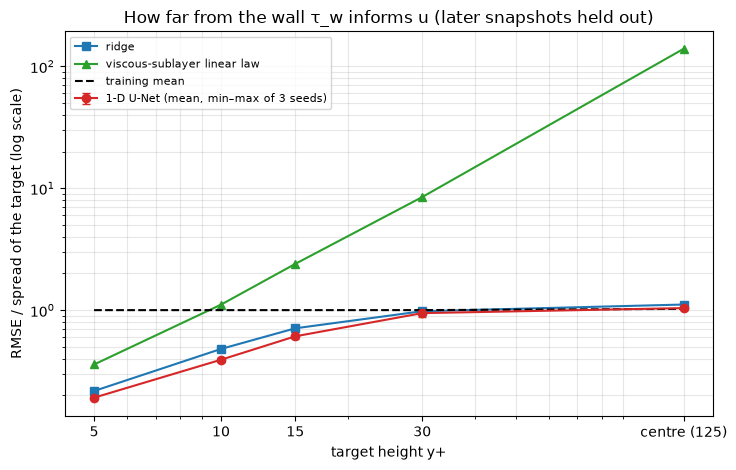

In [8]:
df = pd.DataFrame(rows); df.to_csv(RES / "runs.csv", index=False)
agg = df.groupby(["split", "model", "y_plus"]).agg(mae=("mae", "mean"), mae_min=("mae", "min"), mae_max=("mae", "max"), r=("rmse_over_spread", "mean"),
                                                  r_min=("rmse_over_spread", "min"), r_max=("rmse_over_spread", "max"), spread=("spread", "first")).reset_index()
agg["model"] = agg.model.str.replace(r"ridge \(alpha .*\)", "ridge", regex=True); agg.to_csv(RES / "summary.csv", index=False)
TS = "time (later snapshots held out)"
a = agg[agg.split == TS]
ta = a.pivot(index="y_plus", columns="model", values="r")[["1-D U-Net", "ridge", "viscous-sublayer linear law", "training mean"]]
ta.insert(0, "target spread", a.groupby("y_plus").spread.first()); ta.to_csv(RES / "a_height_table.csv")
print("RMSE divided by the target's spread, time split (U-Net: mean of 3 seeds):"); print(ta.round(4).to_string())
print("\nMAE (stored units):"); print(a.pivot(index="y_plus", columns="model", values="mae").round(4).to_string())
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for mname, c, mk in (("1-D U-Net", "#d62728", "o"), ("ridge", "#1f77b4", "s"), ("viscous-sublayer linear law", "#2ca02c", "^"), ("training mean", "k", "")):
    r = a[a.model == mname].sort_values("y_plus")
    if mname == "1-D U-Net": ax.errorbar(r.y_plus, r.r, yerr=[r.r - r.r_min, r.r_max - r.r], color=c, marker=mk, capsize=3, label="1-D U-Net (mean, min–max of 3 seeds)")
    else: ax.plot(r.y_plus, r.r, color=c, marker=mk or None, ls="--" if mname == "training mean" else "-", label=mname)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(YP); ax.set_xticklabels(["5", "10", "15", "30", "centre (125)"])
ax.set_xlabel("target height y+"); ax.set_ylabel("RMSE / spread of the target (log scale)"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title("How far from the wall τ_w informs u (later snapshots held out)"); fig.tight_layout(); fig.savefig(RES / "a_height.png", dpi=130); plt.show()

## Part (b): generalisation across time and spanwise planes

RMSE divided by the target's spread at y+ = 5 and 10, by split (U-Net: mean of 3 seeds):
split                               random (Stage 1)  time (later snapshots held out)  planes (spanwise planes 48-49 and 80-89 held out)
model                       y_plus                                                                                                   
1-D U-Net                   5.0                      0.1727                           0.1915                                   0.1905
                            10.0                     0.3358                           0.3922                                   0.3939
ridge                       5.0                      0.1806                           0.2173                                   0.2057
                            10.0                     0.4059                           0.4808                                   0.4520
training mean               5.0                      1.0001                           1.0009            

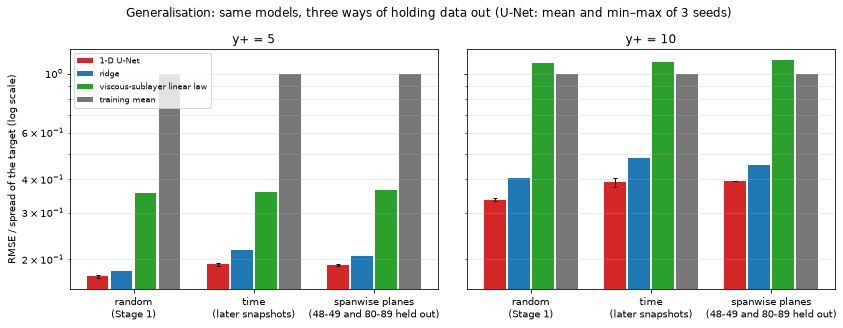

In [9]:
b = agg[agg.y_plus.isin([5.0, 10.0])]
tb = b.pivot_table(index=["model", "y_plus"], columns="split", values="r").reindex(columns=list(SPLITS)); tb.to_csv(RES / "b_generalisation_table.csv")
print("RMSE divided by the target's spread at y+ = 5 and 10, by split (U-Net: mean of 3 seeds):"); print(tb.round(4).to_string())
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
models = ["1-D U-Net", "ridge", "viscous-sublayer linear law", "training mean"]; cols = ["#d62728", "#1f77b4", "#2ca02c", "#777"]
for ax, yp in zip(axs, (5.0, 10.0)):
    for k, (mname, c) in enumerate(zip(models, cols)):
        for s_i, split in enumerate(SPLITS):
            r = b[(b.model == mname) & (b.y_plus == yp) & (b.split == split)].iloc[0]
            x = s_i + (k - 1.5) * 0.2
            ax.bar(x, r.r, width=0.18, color=c, label=mname if s_i == 0 else None)
            if mname == "1-D U-Net": ax.errorbar(x, r.r, yerr=[[r.r - r.r_min], [r.r_max - r.r]], color="k", capsize=2, lw=1)
    ax.set_yscale("log"); ax.set_xticks(range(3)); ax.set_xticklabels(["random\n(Stage 1)", "time\n(later snapshots)", "spanwise planes\n(48-49 and 80-89 held out)"])
    ax.set_title(f"y+ = {yp:.0f}"); ax.grid(alpha=0.3, axis="y", which="both")
axs[0].set_ylabel("RMSE / spread of the target (log scale)"); axs[0].legend(fontsize=8)
fig.suptitle("Generalisation: same models, three ways of holding data out (U-Net: mean and min–max of 3 seeds)"); fig.tight_layout(); fig.savefig(RES / "b_generalisation.png", dpi=130); plt.show()